## Loading the Dataset


In [1]:
# Day 16 – Cell 1
# Imports and device setup

import os
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import torch
import torch.nn as nn

from torch.utils.data import TensorDataset, DataLoader

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("Device:", device)

Device: cpu


In [2]:
# Day 16 – Cell 2
# Dataset path

DATASET_PATH = "/content/drive/MyDrive/IITG dataset/cleaned_dataset"

V1_PATH = os.path.join(
    DATASET_PATH,
    "processed_dataset_v1"
)

print("Dataset path:")
print(V1_PATH)

Dataset path:
/content/drive/MyDrive/IITG dataset/cleaned_dataset/processed_dataset_v1


In [4]:
# Day 16 – Cell 2
# Mount Drive and verify dataset path

from google.colab import drive
import os

drive.mount("/content/drive")

DATASET_PATH = "/content/drive/MyDrive/IITG dataset/cleaned_dataset"
V1_PATH = os.path.join(DATASET_PATH, "processed_dataset_v1")

print("Checking path:")
print(V1_PATH)

print("\nFiles inside processed_dataset_v1:")

if os.path.exists(V1_PATH):
    print(os.listdir(V1_PATH))
else:
    print("processed_dataset_v1 folder NOT FOUND")

Mounted at /content/drive
Checking path:
/content/drive/MyDrive/IITG dataset/cleaned_dataset/processed_dataset_v1

Files inside processed_dataset_v1:
['sequences_v1.npz', 'processing_info_v1.json', 'feature_scaler_v1.pkl', 'gru_best_model.pth', 'tcn_best_model.pth', 'lstm_best_model.pth', 'day15_lstm_best_soh_model.pth']


In [5]:
# Day 16 – Cell 3
# Load sequence dataset

SEQUENCES_PATH = os.path.join(
    V1_PATH,
    "sequences_v1.npz"
)

print("Loading:")
print(SEQUENCES_PATH)

data = np.load(
    SEQUENCES_PATH,
    allow_pickle=True
)

X_sequences = data["X"]
y_soh = data["SoH"]

sequence_battery_ids = data["battery_id"]
sequence_splits = data["split"]

print("\nDataset loaded successfully.")

print("X shape:", X_sequences.shape)
print("SoH shape:", y_soh.shape)
print("Battery ID shape:", sequence_battery_ids.shape)
print("Split shape:", sequence_splits.shape)

print("\nSplit distribution:")
print(
    pd.Series(sequence_splits).value_counts()
)

Loading:
/content/drive/MyDrive/IITG dataset/cleaned_dataset/processed_dataset_v1/sequences_v1.npz

Dataset loaded successfully.
X shape: (2287, 10, 2)
SoH shape: (2287,)
Battery ID shape: (2287,)
Split shape: (2287,)

Split distribution:
train         1516
test           392
validation     379
Name: count, dtype: int64


## Normalizing

In [6]:
# Day 16 – Cell 4
# Normalize SoH

print("Original SoH:")
print("Min:", y_soh.min())
print("Max:", y_soh.max())
print("Mean:", y_soh.mean())

# Convert 0–100 to 0–1
y_soh = y_soh / 100.0

print("\nNormalized SoH:")
print("Min:", y_soh.min())
print("Max:", y_soh.max())
print("Mean:", y_soh.mean())

Original SoH:
Min: 0.0
Max: 100.0
Mean: 72.7266383162617

Normalized SoH:
Min: 0.0
Max: 1.0
Mean: 0.7272663831626169


In [7]:
# Day 16 – Cell 5

train_mask = sequence_splits == "train"
val_mask = sequence_splits == "validation"
test_mask = sequence_splits == "test"

X_train = X_sequences[train_mask]
X_val = X_sequences[val_mask]
X_test = X_sequences[test_mask]

y_train = y_soh[train_mask]
y_val = y_soh[val_mask]
y_test = y_soh[test_mask]

print("Train:", X_train.shape, y_train.shape)
print("Validation:", X_val.shape, y_val.shape)
print("Test:", X_test.shape, y_test.shape)

Train: (1516, 10, 2) (1516,)
Validation: (379, 10, 2) (379,)
Test: (392, 10, 2) (392,)


In [8]:
# Day 16 – Cell 6

BATCH_SIZE = 32

train_dataset = TensorDataset(
    torch.tensor(X_train, dtype=torch.float32),
    torch.tensor(y_train, dtype=torch.float32)
)

val_dataset = TensorDataset(
    torch.tensor(X_val, dtype=torch.float32),
    torch.tensor(y_val, dtype=torch.float32)
)

test_dataset = TensorDataset(
    torch.tensor(X_test, dtype=torch.float32),
    torch.tensor(y_test, dtype=torch.float32)
)

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True
)

val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False
)

test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False
)

print("DataLoaders ready.")

DataLoaders ready.


## GRU MODEL

In [9]:
# Day 16 – Cell 7

class PrognosticGRU(nn.Module):

    def __init__(
        self,
        input_dim,
        hidden_dim=64,
        num_layers=2,
        output_dim=1
    ):
        super().__init__()

        self.gru = nn.GRU(
            input_size=input_dim,
            hidden_size=hidden_dim,
            num_layers=num_layers,
            batch_first=True,
            dropout=0.2
        )

        self.fc1 = nn.Linear(
            hidden_dim,
            32
        )

        self.relu = nn.ReLU()

        self.fc2 = nn.Linear(
            32,
            output_dim
        )

    def forward(self, x):

        out, _ = self.gru(x)

        out = out[:, -1, :]

        out = self.fc1(out)
        out = self.relu(out)
        out = self.fc2(out)

        return out.squeeze(-1)


input_dim = X_train.shape[2]

model = PrognosticGRU(
    input_dim=input_dim,
    hidden_dim=64,
    num_layers=2,
    output_dim=1
).to(device)

print(model)

PrognosticGRU(
  (gru): GRU(2, 64, num_layers=2, batch_first=True, dropout=0.2)
  (fc1): Linear(in_features=64, out_features=32, bias=True)
  (relu): ReLU()
  (fc2): Linear(in_features=32, out_features=1, bias=True)
)


In [10]:
# Day 16 – Cell 8

criterion = nn.MSELoss()

optimizer = torch.optim.Adam(
    model.parameters(),
    lr=0.001
)

print("Loss:", criterion)
print("Optimizer:", optimizer)

Loss: MSELoss()
Optimizer: Adam (
Parameter Group 0
    amsgrad: False
    betas: (0.9, 0.999)
    capturable: False
    decoupled_weight_decay: False
    differentiable: False
    eps: 1e-08
    foreach: None
    fused: None
    lr: 0.001
    maximize: False
    weight_decay: 0
)


## Training GRU Model

In [11]:
# Day 16 – Cell 9

NUM_EPOCHS = 30

train_losses = []
val_losses = []

best_val_loss = float("inf")
best_epoch = 0

CHECKPOINT_PATH = os.path.join(
    V1_PATH,
    "day16_gru_best_soh_model.pth"
)

for epoch in range(NUM_EPOCHS):

    # Training
    model.train()

    train_loss_total = 0.0

    for X_batch, y_batch in train_loader:

        X_batch = X_batch.to(device)
        y_batch = y_batch.to(device)

        optimizer.zero_grad()

        predictions = model(X_batch)

        loss = criterion(
            predictions,
            y_batch
        )

        loss.backward()
        optimizer.step()

        train_loss_total += (
            loss.item() * X_batch.size(0)
        )

    train_loss = (
        train_loss_total /
        len(train_loader.dataset)
    )

    # Validation
    model.eval()

    val_loss_total = 0.0

    with torch.no_grad():

        for X_batch, y_batch in val_loader:

            X_batch = X_batch.to(device)
            y_batch = y_batch.to(device)

            predictions = model(X_batch)

            loss = criterion(
                predictions,
                y_batch
            )

            val_loss_total += (
                loss.item() * X_batch.size(0)
            )

    val_loss = (
        val_loss_total /
        len(val_loader.dataset)
    )

    train_losses.append(train_loss)
    val_losses.append(val_loss)

    # Save best model
    if val_loss < best_val_loss:

        best_val_loss = val_loss
        best_epoch = epoch + 1

        torch.save(
            model.state_dict(),
            CHECKPOINT_PATH
        )

    print(
        f"Epoch {epoch+1:02d}/{NUM_EPOCHS} | "
        f"Train Loss: {train_loss:.6f} | "
        f"Val Loss: {val_loss:.6f}"
    )

print("\nTraining completed.")
print("Best Epoch:", best_epoch)
print("Best Validation Loss:", best_val_loss)
print("Checkpoint:", CHECKPOINT_PATH)

Epoch 01/30 | Train Loss: 0.251990 | Val Loss: 0.078641
Epoch 02/30 | Train Loss: 0.055797 | Val Loss: 0.054660
Epoch 03/30 | Train Loss: 0.048803 | Val Loss: 0.065843
Epoch 04/30 | Train Loss: 0.049023 | Val Loss: 0.062460
Epoch 05/30 | Train Loss: 0.049417 | Val Loss: 0.071054
Epoch 06/30 | Train Loss: 0.049353 | Val Loss: 0.072123
Epoch 07/30 | Train Loss: 0.047747 | Val Loss: 0.072631
Epoch 08/30 | Train Loss: 0.047453 | Val Loss: 0.071685
Epoch 09/30 | Train Loss: 0.048597 | Val Loss: 0.068965
Epoch 10/30 | Train Loss: 0.048502 | Val Loss: 0.067577
Epoch 11/30 | Train Loss: 0.048886 | Val Loss: 0.070098
Epoch 12/30 | Train Loss: 0.048196 | Val Loss: 0.073860
Epoch 13/30 | Train Loss: 0.047382 | Val Loss: 0.071307
Epoch 14/30 | Train Loss: 0.046585 | Val Loss: 0.068772
Epoch 15/30 | Train Loss: 0.047398 | Val Loss: 0.067579
Epoch 16/30 | Train Loss: 0.047466 | Val Loss: 0.071320
Epoch 17/30 | Train Loss: 0.046396 | Val Loss: 0.081583
Epoch 18/30 | Train Loss: 0.045848 | Val Loss: 0

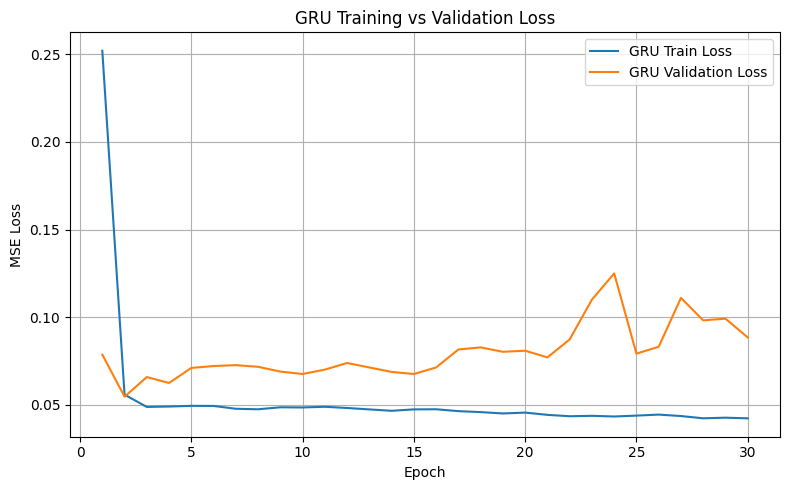

In [12]:
# Day 16 – Cell 10

plt.figure(figsize=(8, 5))

plt.plot(
    range(1, NUM_EPOCHS + 1),
    train_losses,
    label="GRU Train Loss"
)

plt.plot(
    range(1, NUM_EPOCHS + 1),
    val_losses,
    label="GRU Validation Loss"
)

plt.xlabel("Epoch")
plt.ylabel("MSE Loss")

plt.title("GRU Training vs Validation Loss")

plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()

In [13]:
# Day 16 – Cell 11

model.load_state_dict(
    torch.load(
        CHECKPOINT_PATH,
        map_location=device
    )
)

model.eval()

print("Best GRU model loaded.")
print("Best Epoch:", best_epoch)
print("Best Validation Loss:", best_val_loss)

Best GRU model loaded.
Best Epoch: 2
Best Validation Loss: 0.05465997753561644


In [14]:
# Day 16 – Cell 12

all_predictions = []
all_targets = []

model.eval()

with torch.no_grad():

    for X_batch, y_batch in test_loader:

        X_batch = X_batch.to(device)

        predictions = model(X_batch)

        all_predictions.append(
            predictions.cpu().numpy()
        )

        all_targets.append(
            y_batch.numpy()
        )

y_pred_gru = np.concatenate(all_predictions)
y_true_gru = np.concatenate(all_targets)

print("Prediction completed.")

print("Actual:", y_true_gru.shape)
print("Predicted:", y_pred_gru.shape)

Prediction completed.
Actual: (392,)
Predicted: (392,)


In [15]:
# Day 16 – Cell 13

mae_gru = mean_absolute_error(
    y_true_gru,
    y_pred_gru
)

rmse_gru = np.sqrt(
    mean_squared_error(
        y_true_gru,
        y_pred_gru
    )
)

mape_gru = np.mean(
    np.abs(
        (y_true_gru - y_pred_gru) /
        np.clip(
            np.abs(y_true_gru),
            1e-3,
            None
        )
    )
) * 100

r2_gru = r2_score(
    y_true_gru,
    y_pred_gru
)

print("GRU Test Set Performance")
print("=" * 35)

print(f"MAE  : {mae_gru:.6f}")
print(f"RMSE : {rmse_gru:.6f}")
print(f"MAPE : {mape_gru:.4f}%")
print(f"R²   : {r2_gru:.6f}")

GRU Test Set Performance
MAE  : 0.143874
RMSE : 0.195698
MAPE : 815.0989%
R²   : -0.605318


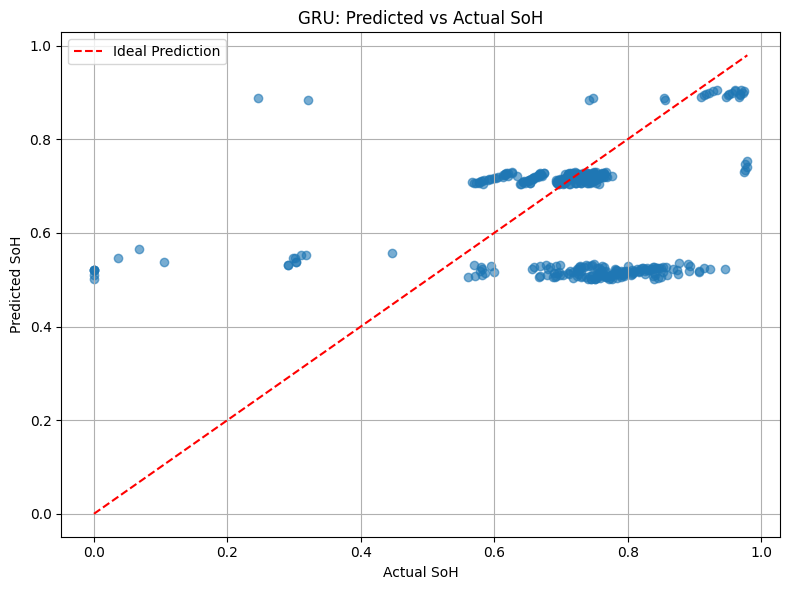

In [18]:
# Day 16 – Cell 14

plt.figure(figsize=(8, 6))

plt.scatter(
    y_true_gru,
    y_pred_gru,
    alpha=0.6
)

min_val = min(
    y_true_gru.min(),
    y_pred_gru.min()
)

max_val = max(
    y_true_gru.max(),
    y_pred_gru.max()
)

plt.plot(
    [min_val, max_val],
    [min_val, max_val],
    "r--",
    label="Ideal Prediction"
)

plt.xlabel("Actual SoH")
plt.ylabel("Predicted SoH")

plt.title("GRU: Predicted vs Actual SoH")

plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()

## Summary

In [19]:
# Day 16 – Cell 16

total_parameters = sum(
    p.numel()
    for p in model.parameters()
)

print("GRU MODEL SUMMARY")
print("=" * 40)

print("Input Features:", input_dim)
print("Sequence Length:", X_train.shape[1])
print("Hidden Size:", 64)
print("GRU Layers:", 2)
print("Dropout:", 0.2)
print("Batch Size:", BATCH_SIZE)
print("Epochs:", NUM_EPOCHS)

print("\nBest Epoch:", best_epoch)
print("Best Validation Loss:", best_val_loss)

print("\nTest Performance")
print("----------------")
print("MAE :", mae_gru)
print("RMSE:", rmse_gru)
print("MAPE:", mape_gru)
print("R²  :", r2_gru)

print("\nTotal Parameters:", total_parameters)

print("\nCheckpoint:")
print(CHECKPOINT_PATH)

GRU MODEL SUMMARY
Input Features: 2
Sequence Length: 10
Hidden Size: 64
GRU Layers: 2
Dropout: 0.2
Batch Size: 32
Epochs: 30

Best Epoch: 2
Best Validation Loss: 0.05465997753561644

Test Performance
----------------
MAE : 0.14387370645999908
RMSE: 0.19569809996650364
MAPE: 815.09894
R²  : -0.6053180694580078

Total Parameters: 40129

Checkpoint:
/content/drive/MyDrive/IITG dataset/cleaned_dataset/processed_dataset_v1/day16_gru_best_soh_model.pth
